# 02 · Probabilistic CLV: BG/NBD + Gamma-Gamma

**Question:** how many orders, and how much revenue, will each customer bring in the next 12 months,
and which acquisition channels bring the most valuable customers?

**Method:** the BG/NBD family of models (Fader, Hardie & Lee, 2005), which describe non-contractual
customers with two latent processes:

- while *alive*, a customer buys at a personal rate λ (Poisson), with λ ~ Gamma(r, α) across customers;
- after each purchase they *drop out* with a personal probability p, with p ~ Beta(a, b).

Gamma-Gamma then models the order value, and the two together give a probabilistic CLV. The fit uses
only frequency, recency and customer age (`T`), no features. It's checked three ways:

1. **holdout:** fit on the period before 1 November 2025, predict the next 12 months' purchases, and
   compare predicted with actual per decile of predicted purchases;
2. **ground truth:** #131's generator planted the segments and purchase rates
   (`raw.customer_truth`), so we can check that the model *recovers* them. The truth is only read
   here, for evaluation, never as an input;
3. **business:** 12-month CLV per customer and per acquisition channel.

Two modelling choices, both decided from how the business works rather than from the holdout:

- **MBG/NBD** (Batislam et al., 2007) instead of classic BG/NBD. Classic BG/NBD assumes a customer is
  alive until at least their first *repeat* purchase, but here many customers try the shop once and
  never come back: churn can follow any order, including the first. MBG/NBD allows exactly that.
  Classic BG/NBD is fitted alongside for comparison.
- A **seasonally adjusted clock** (`jassmin_ml/clock.py`): BG/NBD assumes a constant purchase rate,
  but this shop's demand doubles around 8 March and in December and sags in summer, so time is
  measured in expected-demand weeks instead of calendar weeks.

In [1]:
import os
import warnings

# PyTensor compiles to C when a compiler is around; without one it runs in Python mode, which is fast
# enough for a MAP fit. Say so explicitly, so it doesn't warn, and keep library warnings out of the
# saved outputs.
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pymc_marketing.clv import BetaGeoModel, GammaGammaModel, ModifiedBetaGeoModel
from scipy.optimize import linear_sum_assignment
from scipy.stats import pearsonr, spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

from jassmin_ml import clock, metrics, plots
from jassmin_ml.db import read_mart
from jassmin_ml.seed import SEED, set_seeds
from jassmin_ml.truth import PLANTED, load_truth

rng = set_seeds()
plots.use_style()
pd.set_option("display.precision", 3)

CALIBRATION_END = pd.Timestamp("2025-10-31")  # last calibration day (Kyiv)
HOLDOUT_END = pd.Timestamp("2026-10-31")  # 12 months of holdout
DATA_END = HOLDOUT_END

## Transactions

A purchase is a revenue order (paid, shipped or completed; orders cancelled because the payment
failed don't count), one per customer and Kyiv day, valued at its net revenue after discounts.

In [2]:
tx = read_mart(
    """
    select customer_key, order_date, sum(net_revenue)::float8 as net_revenue
    from marts.fct_orders
    where is_revenue
    group by customer_key, order_date
    """
)
tx["order_date"] = pd.to_datetime(tx["order_date"])
calendar = read_mart("select date_day from marts.dim_date where date_day between '2024-01-01' and :end order by 1", {"end": DATA_END.date()})
days = pd.to_datetime(calendar["date_day"])
print(f"{len(tx):,} purchase days by {tx['customer_key'].nunique():,} customers, {days.min():%Y-%m-%d} → {days.max():%Y-%m-%d}")

16,116 purchase days by 8,396 customers, 2024-01-01 → 2026-10-31


## The seasonally adjusted clock

Daily *repeat* orders (not a customer's first) per customer acquired so far, modelled with a Poisson
GLM: month of year, the gift windows (14 February week, 1–8 March, Black Friday week, St Nicholas,
the New Year rush) and a linear trend. The calibration clock is estimated on calibration days only,
so nothing from the holdout leaks into it; the holdout days get the index from their calendar
position.

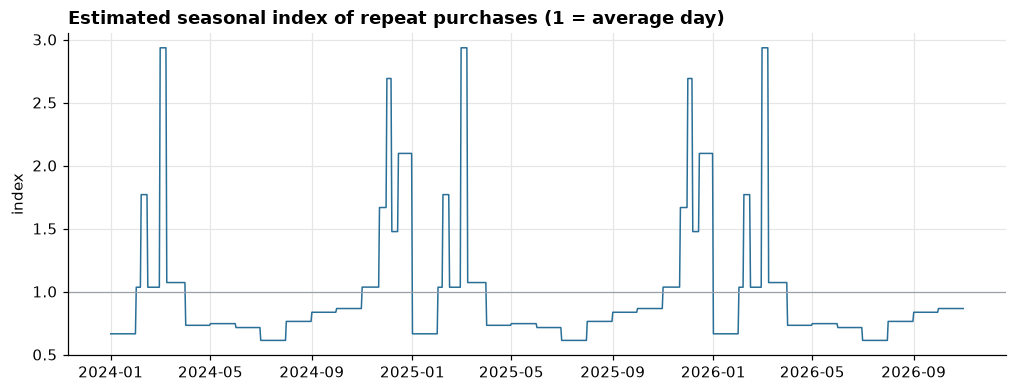

,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,valentines_week,womens_day_week,black_friday_week,st_nicholas,new_year_rush
multiplier vs January,1.56,1.61,1.1,1.12,1.07,0.92,1.15,1.26,1.3,1.56,2.22,1.71,2.74,1.61,1.82,1.42


In [3]:
def build_clock(fit_end: pd.Timestamp) -> tuple[pd.Series, pd.Series, object]:
    first_day = tx.groupby("customer_key")["order_date"].transform("min")
    repeat = tx[tx["order_date"] > first_day]
    repeat_orders = repeat.groupby("order_date").size().reindex(days, fill_value=0).to_numpy()
    acquired = tx.groupby("customer_key")["order_date"].min().value_counts()
    base = acquired.reindex(days, fill_value=0).cumsum().shift(1, fill_value=0).to_numpy()
    # From February 2024: in January the customer base is still tiny.
    fit_mask = ((days >= "2024-02-01") & (days <= fit_end)).to_numpy()
    year = (days.dt.year == 2025).to_numpy()
    index, glm = clock.fit_seasonal_index(days, repeat_orders, base, fit_mask, year)
    return index, clock.adjusted_weeks(index), glm


cal_index, cal_clock, cal_glm = build_clock(CALIBRATION_END)
full_index, full_clock, full_glm = build_clock(DATA_END)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(full_index.index, full_index, color=plots.ACCENT, lw=1)
ax.axhline(1, color=plots.MUTED, lw=0.8)
ax.set_title("Estimated seasonal index of repeat purchases (1 = average day)")
ax.set_ylabel("index")
plt.show()
pd.Series(np.exp(full_glm.params.drop(["const", "trend"])), name="multiplier vs January").round(2).to_frame().T

The index recovers the shop's calendar without being told the multipliers: the week before 8 March
is the biggest (× 2.7 on top of an already strong March), then St Nicholas Day, the 14 February week,
Black Friday week and the New Year rush, with December the strongest month overall; January and
July are the troughs. One adjusted week is one calendar week on average over a year.

## 1. Calibration and holdout

Customers with a first purchase on or before 31 October 2025; their purchases up to that day are the
calibration data, and the next 12 months the holdout.

In [4]:
calibration = clock.rfm_on_clock(tx, cal_clock, CALIBRATION_END)
holdout = tx[(tx["order_date"] > CALIBRATION_END) & (tx["order_date"] <= HOLDOUT_END)]
calibration["holdout_purchases"] = (
    holdout.groupby("customer_key").size().reindex(calibration["customer_id"], fill_value=0).to_numpy()
)
horizon = cal_clock[HOLDOUT_END] - cal_clock[CALIBRATION_END]
print(f"{len(calibration):,} customers; holdout horizon {horizon:.1f} adjusted weeks")
calibration[["frequency", "recency", "T", "holdout_purchases"]].describe().T

3,780 customers; holdout horizon 52.1 adjusted weeks


,count,mean,std,min,25%,50%,75%,max
frequency,3780.0,0.662,1.593,0.0,0.000,0.000,1.000,27.000
recency,3780.0,6.441,13.965,0.0,0.000,0.000,4.226,86.221
T,3780.0,32.925,22.531,0.0,14.622,29.231,49.157,89.284
holdout_purchases,3780.0,0.701,1.665,0.0,0.000,0.000,1.000,25.000


For comparison, the same customers on the plain calendar clock (weeks since first purchase).

In [5]:
plain_clock = pd.Series((np.arange(len(days)) + 1) / 7.0, index=pd.DatetimeIndex(days))
calibration_plain = clock.rfm_on_clock(tx, plain_clock, CALIBRATION_END)
assert (calibration_plain["customer_id"] == calibration["customer_id"]).all()
horizon_plain = plain_clock[HOLDOUT_END] - plain_clock[CALIBRATION_END]

COLUMNS = ["customer_id", "frequency", "recency", "T"]


def fit(model_class, data: pd.DataFrame):
    model = model_class()
    model.fit(data[COLUMNS], method="map", progressbar=False, random_seed=SEED)
    return model


def predict(model, data: pd.DataFrame, future_t: float) -> np.ndarray:
    return model.expected_purchases(data=data[COLUMNS], future_t=future_t).squeeze().to_numpy()


runs = {
    "BG/NBD, calendar clock": (BetaGeoModel, calibration_plain, horizon_plain),
    "BG/NBD, seasonal clock": (BetaGeoModel, calibration, horizon),
    "MBG/NBD, seasonal clock": (ModifiedBetaGeoModel, calibration, horizon),
}
predictions, decile_tables, rows = {}, {}, []
actual = calibration["holdout_purchases"]
for name, (model_class, data, future_t) in runs.items():
    model = fit(model_class, data)
    predictions[name] = predict(model, data, future_t)
    table = metrics.decile_table(pd.Series(predictions[name]), actual.reset_index(drop=True))
    decile_tables[name] = table
    rows.append(
        {
            "model": name,
            "predicted": predictions[name].sum(),
            "actual": actual.sum(),
            "total_error": predictions[name].sum() / actual.sum() - 1,
            "max_decile_error": table["relative_error"].max(),
            "deciles_within_15%": int((table["relative_error"] <= 0.15).sum()),
        }
    )
comparison = pd.DataFrame(rows).set_index("model")
comparison

,predicted,actual,total_error,max_decile_error,deciles_within_15%
model,,,,,
"BG/NBD, calendar clock",2239.743,2649,-0.154,0.305,6
"BG/NBD, seasonal clock",2741.291,2649,0.035,0.407,6
"MBG/NBD, seasonal clock",2684.540,2649,0.013,0.185,9


On the calendar clock BG/NBD underestimates the holdout year by about 15 %: the calibration period
ends after a slow summer, so recent behaviour looks weaker than the customers really are. The
seasonal clock removes that bias in the total. MBG/NBD, which lets customers drop out after their
first order, fixes the bottom deciles (one-time buyers that classic BG/NBD keeps "alive" forever).

**MBG/NBD on the seasonal clock is the model used from here on.** Its decile table:

In [6]:
MODEL = "MBG/NBD, seasonal clock"
deciles = metrics.merge_low_deciles(decile_tables[MODEL], min_actual=30)
deciles

,customers,predicted,actual,relative_error,group
decile,,,,,
1,378,45.452,47.0,0.033,1
2,378,65.971,62.0,0.064,2
3,378,88.711,80.0,0.109,3
4,378,114.158,116.0,0.016,4
5,378,144.599,168.0,0.139,5
6,378,182.626,224.0,0.185,6
7,378,234.889,231.0,0.017,7
8,378,302.334,304.0,0.005,8
9,378,426.704,379.0,0.126,9


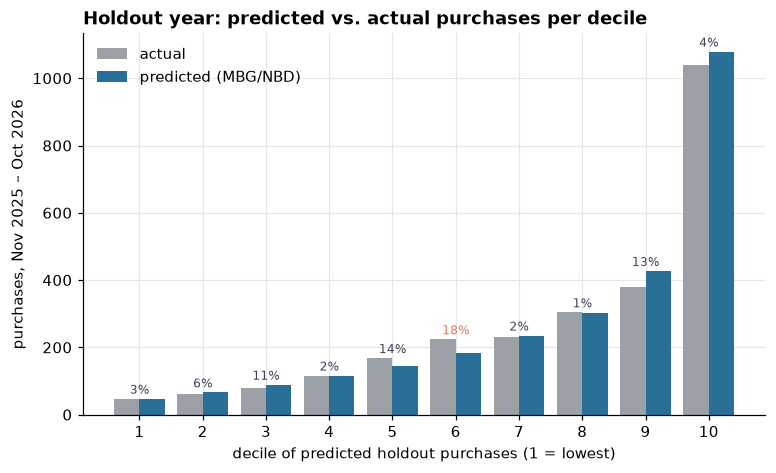

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(deciles))
ax.bar(x - 0.2, deciles["actual"], width=0.4, color=plots.MUTED, label="actual")
ax.bar(x + 0.2, deciles["predicted"], width=0.4, color=plots.ACCENT, label="predicted (MBG/NBD)")
for i, (_, row) in enumerate(deciles.iterrows()):
    ax.text(i, max(row["actual"], row["predicted"]) + 15, f"{row['relative_error']:.0%}", ha="center", fontsize=8,
            color=plots.PALETTE[1] if row["relative_error"] > 0.15 else plots.PALETTE[2])
ax.set_xticks(x, deciles["group"])
ax.set_xlabel("decile of predicted holdout purchases (1 = lowest)")
ax.set_ylabel("purchases, Nov 2025 – Oct 2026")
ax.set_title("Holdout year: predicted vs. actual purchases per decile")
ax.legend(loc="upper left")
plots.save_figure(fig, "02_holdout_deciles")
plt.show()

The classic check by calibration frequency (customers grouped by how many repeat purchases they made
before November 2025):

In [8]:
by_frequency = (
    calibration.assign(predicted=predictions[MODEL], group=calibration["frequency"].clip(upper=7))
    .groupby("group")
    .agg(customers=("customer_id", "size"), predicted=("predicted", "sum"), actual=("holdout_purchases", "sum"))
)
by_frequency["relative_error"] = (by_frequency["predicted"] - by_frequency["actual"]).abs() / by_frequency["actual"]
by_frequency.index = [str(i) if i < 7 else "7+" for i in by_frequency.index]
by_frequency.index.name = "repeat purchases before Nov 2025"
by_frequency

,customers,predicted,actual,relative_error
repeat purchases before Nov 2025,,,,
0,2659,1019.605,1069,0.046
1,600,538.958,533,0.011
2,238,337.953,320,0.056
3,121,232.298,247,0.060
4,51,109.228,103,0.060
5,27,81.287,84,0.032
6,24,62.238,30,1.075
7+,60,302.973,263,0.152


Grouped by calibration frequency, the predictions are within about 6 % for customers with 0–5
repeat purchases, who are 98 % of the customers; the groups above that hold a few dozen customers
each and are noisy. The two deciles that miss by more than 15 % (5 and 6, under-predicted) are
customers *without* a repeat purchase yet, who are ranked only by how long ago they first bought.
A plausible cause is the seasonal index itself, estimated from under two years of calibration data
with a single observation of most months; a longer history would pin it down better.

## 2. Does the model recover the planted customers?

Refit on all the data (to 31 October 2026) and compare each customer's posterior purchase rate λ̂
and probability of being alive with the generator's truth. For MBG/NBD the posterior mean rate is
P(alive)·(r + x)/(α + T) + (1 − P(alive))·(r + x)/(α + t_x), in adjusted weeks, × 52.18 per year.

In [9]:
full = clock.rfm_on_clock(tx, full_clock, DATA_END)
mbg = fit(ModifiedBetaGeoModel, full)
params = mbg.fit_summary()
display(params.to_frame("MAP").T)
full["p_alive"] = mbg.expected_probability_alive(data=full[COLUMNS]).squeeze().to_numpy()
r, alpha = params["r"], params["alpha"]
x, recency, age = full["frequency"], full["recency"], full["T"]
full["rate_per_year"] = 52.18 * (
    full["p_alive"] * (r + x) / (alpha + age) + (1 - full["p_alive"]) * (r + x) / (alpha + recency)
)

truth = load_truth().set_index("customer_key")
joined = full.join(truth, on="customer_id", how="inner")
print(f"{len(joined):,} of {len(full):,} customers have a ground truth (guests don't)")

rho = spearmanr(joined["rate_per_year"], joined["purchase_rate"]).statistic
alive_now = joined["churned_at"].isna()
auc_alive = roc_auc_score(alive_now, joined["p_alive"])
segments = joined.groupby("segment", observed=True).agg(
    customers=("customer_id", "size"),
    true_rate=("purchase_rate", "mean"),
    recovered_rate=("rate_per_year", "mean"),
    true_alive=("churned_at", lambda s: s.isna().mean()),
    p_alive=("p_alive", "mean"),
)
segments.insert(1, "planted_mean_rate", [PLANTED[s][1] for s in segments.index])
print(f"Spearman ρ(recovered rate, true rate) = {rho:.2f}; ROC-AUC of P(alive) for 'still alive' = {auc_alive:.2f}")
segments

,alpha,phi_dropout,kappa_dropout,r,a,b
MAP,12.609,0.373,1.862,0.597,0.695,1.167


8,138 of 8,396 customers have a ground truth (guests don't)
Spearman ρ(recovered rate, true rate) = 0.46; ROC-AUC of P(alive) for 'still alive' = 0.74


,customers,planted_mean_rate,true_rate,recovered_rate,true_alive,p_alive
segment,,,,,,
loyal,743,6.0,6.327,4.958,0.666,0.592
regular,1953,3.0,3.084,2.980,0.484,0.505
occasional,2855,1.3,1.369,2.119,0.373,0.462
one_time,2587,0.6,0.625,1.821,0.099,0.424


The recovered rates rank the segments in the right order, and P(alive) separates the customers who
are really still active from the churned ones (ROC-AUC well above 0.5). The extremes are shrunk
towards the mean, as a Bayesian model should for customers with one or two purchases: a one-time
buyer and an occasional buyer look identical after a single order.

**Unsupervised segment recovery:** four k-means clusters on (log rate, logit P(alive),
log(1 + frequency)), compared with the planted segments by the adjusted Rand index (ARI) and by
accuracy after the best one-to-one matching of clusters to segments. Chance level is the ARI of
shuffled labels (500 permutations) and the share of the largest segment.

In [10]:
features = np.column_stack(
    [
        np.log(joined["rate_per_year"]),
        np.log(joined["p_alive"] / (1 - joined["p_alive"]).clip(lower=1e-9)),
        np.log1p(joined["frequency"]),
    ]
)
clusters = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit_predict(StandardScaler().fit_transform(features))
true_codes = joined["segment"].cat.codes.to_numpy()
ari = adjusted_rand_score(true_codes, clusters)
contingency = pd.crosstab(joined["segment"], clusters)
row_ind, col_ind = linear_sum_assignment(-contingency.to_numpy())
accuracy = contingency.to_numpy()[row_ind, col_ind].sum() / len(joined)
permuted = np.array([adjusted_rand_score(rng.permutation(true_codes), clusters) for _ in range(500)])
majority = joined["segment"].value_counts(normalize=True).max()
contingency.columns = [f"cluster {c}" for c in contingency.columns]
print(f"ARI {ari:.3f} (shuffled 99th percentile {np.quantile(permuted, 0.99):.3f}); "
      f"matched accuracy {accuracy:.1%} (largest segment {majority:.1%})")
contingency

ARI 0.142 (shuffled 99th percentile 0.004); matched accuracy 45.4% (largest segment 35.1%)


,cluster 0,cluster 1,cluster 2,cluster 3
segment,,,,
loyal,132,144,142,325
regular,437,849,347,320
occasional,569,1958,258,70
one_time,91,2452,41,3


Well above chance, though far from perfect. One cluster collects the single-order customers: almost
all one-time buyers and most occasional ones, which purchase history alone can't tell apart (with one
order there is nothing to tell them apart). The cluster of the most active customers is almost
entirely loyal and regular customers. Loyal customers who recently joined, with one or two orders so
far, are spread over the other clusters: the model needs a few purchases to recognise them.

## 3. Order value (Gamma-Gamma) and 12-month CLV

Gamma-Gamma assumes order value is independent of purchase frequency; check on repeat buyers first.

In [11]:
# Gamma-Gamma's order value is the mean of the *repeat* purchases (the first one is excluded, as in
# Fader, Hardie & Lee's formulation); customers without a repeat purchase get 0 and aren't fitted.
first_day = tx.groupby("customer_key")["order_date"].transform("min")
values = (
    tx[tx["order_date"] > first_day].groupby("customer_key")["net_revenue"].mean().rename("monetary_value")
)
full = full.join(values, on="customer_id")
full["monetary_value"] = full["monetary_value"].fillna(0.0)
repeaters = full[full["frequency"] > 0]
corr = pearsonr(repeaters["frequency"], repeaters["monetary_value"]).statistic
print(f"{len(repeaters):,} repeat buyers; correlation(frequency, mean order value) = {corr:.3f}")

gg = GammaGammaModel()
gg.fit(repeaters[["customer_id", "monetary_value", "frequency"]], method="map", progressbar=False, random_seed=SEED)
display(gg.fit_summary().to_frame("MAP").T)

2,847 repeat buyers; correlation(frequency, mean order value) = -0.007


,p,q,v
MAP,13.357,3.059,142.096


The correlation is close to zero, so the independence assumption holds. CLV over the next 12 months
with a 1 % monthly discount rate (an assumption: roughly the shop's cost of capital), for every
customer, using the Gamma-Gamma expected order value: the customer's own average shrunk towards the
population mean, and the population mean itself for customers without a repeat purchase.

In [12]:
spend = gg.expected_customer_spend(data=full[["customer_id", "monetary_value", "frequency"]]).squeeze().to_numpy()
full["expected_order_value"] = spend
full["expected_purchases_12m"] = predict(mbg, full, 52.18)
clv = gg.expected_customer_lifetime_value(
    transaction_model=mbg,
    data=full[["customer_id", "frequency", "recency", "T", "monetary_value"]],
    future_t=12,
    discount_rate=0.01,
    time_unit="W",
)
full["clv_12m"] = clv.squeeze().to_numpy()
full[["expected_purchases_12m", "expected_order_value", "clv_12m", "p_alive"]].describe().T

,count,mean,std,min,25%,50%,75%,max
expected_purchases_12m,8396.0,0.657,1.015,1.191e-04,0.146,0.332,0.729,17.181
expected_order_value,8396.0,888.566,215.049,1.764e+02,921.762,921.762,921.762,4237.765
clv_12m,8396.0,525.226,817.686,1.356e-01,120.863,266.175,585.345,12250.898
p_alive,8396.0,0.470,0.171,3.591e-05,0.353,0.450,0.573,0.973


In [13]:
channels = read_mart("select customer_key, acquisition_channel from marts.dim_customers")
by_channel = (
    full.join(channels.set_index("customer_key"), on="customer_id")
    .groupby("acquisition_channel")
    .agg(
        customers=("customer_id", "size"),
        mean_clv_12m=("clv_12m", "mean"),
        total_clv_12m=("clv_12m", "sum"),
        p_alive=("p_alive", "mean"),
        orders_next_12m=("expected_purchases_12m", "mean"),
    )
    .sort_values("total_clv_12m", ascending=False)
)
by_channel["share_of_clv"] = by_channel["total_clv_12m"] / by_channel["total_clv_12m"].sum()
by_channel

,customers,mean_clv_12m,total_clv_12m,p_alive,orders_next_12m,share_of_clv
acquisition_channel,,,,,,
instagram,2752,553.393,1.523e+06,0.475,0.695,0.345
google,1834,528.638,9.695e+05,0.474,0.668,0.220
direct,1293,523.367,6.767e+05,0.470,0.657,0.153
telegram,971,503.803,4.892e+05,0.467,0.624,0.111
referral,732,533.325,3.904e+05,0.472,0.661,0.089
facebook,556,542.361,3.016e+05,0.465,0.662,0.068
guest,258,230.562,5.949e+04,0.419,0.266,0.013


In [14]:
top = full.sort_values("clv_12m", ascending=False)
top_decile_share = top["clv_12m"].head(len(top) // 10).sum() / top["clv_12m"].sum()
print(f"Expected revenue from existing customers, next 12 months: {full['clv_12m'].sum():,.0f} UAH; "
      f"the top 10 % of customers hold {top_decile_share:.0%} of it.")

Expected revenue from existing customers, next 12 months: 4,409,799 UAH; the top 10 % of customers hold 46% of it.


**Business action.** Expected 12-month value is concentrated in a small group of customers, and per
customer the channels differ less than their volumes do, so acquisition budget should follow
volume × CLV per channel (the `total_clv_12m` column), and retention effort should go to the top
CLV decile, ranked by this model rather than by past spend alone (P(alive) discounts big spenders who
have gone quiet).

## Checks

In [15]:
mbg_row = comparison.loc[MODEL]
plain_row = comparison.loc["BG/NBD, calendar clock"]
decile_criterion_met = bool((deciles["relative_error"] <= 0.15).all())
print(f"Holdout: total error {mbg_row['total_error']:+.1%}, {int(mbg_row['deciles_within_15%'])}/10 deciles within 15 %, "
      f"max decile error {mbg_row['max_decile_error']:.0%}; every decile within 15 %: {decile_criterion_met}")
assert abs(mbg_row["total_error"]) < 0.05, "the holdout total should be within 5 %"
assert abs(mbg_row["total_error"]) < abs(plain_row["total_error"]), "the seasonal clock should beat the calendar clock"
assert mbg_row["max_decile_error"] < plain_row["max_decile_error"]
# Ground truth, above chance:
assert ari > np.quantile(permuted, 0.99), "segments should match the truth above chance (ARI)"
assert accuracy > majority, "matched accuracy should beat the largest segment's share"
assert rho > 0.3 and auc_alive > 0.6
assert segments["recovered_rate"].is_monotonic_decreasing, "recovered rates should rank the segments"
assert abs(corr) < 0.2, "Gamma-Gamma needs order value independent of frequency"
print("02 checks passed")

Holdout: total error +1.3%, 9/10 deciles within 15 %, max decile error 18%; every decile within 15 %: False
02 checks passed
